In [1]:
# Import the packages
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn import set_config

import joblib
from pathlib import Path

pd.set_option("display.max_colwidth", None)

# Load the feature engineered Data for France 2024 (cleaned)

In [2]:
df_2024 = pd.read_csv("../data/processed/EU/2024_FR_cleaned.csv")
# Clean column headers (removes accidental spaces)
df_2024.columns = df_2024.columns.str.strip()

# Check dataset dimensions and view first few rows
print(f"Dataset shape: {df_2024.shape[0]} rows, {df_2024.shape[1]} columns")
df_2024.head()
display(df_2024.head())
display(df_2024.info())

Dataset shape: 115275 rows, 22 columns


,VFN,Tan,T,Va,Ve,Mk,Cn,Ct,m (kg),Mt,...,ec (cm3),ep (KW),z (Wh/km),IT,Erwltp (g/km),Fuel consumption,RLFI,Electric range (km),r,Ewltp (g/km)
0,IP - 0015 - ZHW-1,E3*2007/46*0616*02,636,BAAA,AAAAAAAAAAA,AUTOMOBILI LAMBORGHINI S.P.A.,URUS,M1G,2272.0,2525.0,...,3996.0,478.0,0.0,e3 29,1.3,12.7,NaN,0.0,1,325.0
1,IP-0-SCC-1,E4*2018/858*00092*02,TYPE131,1B,1,LOTUS,EMIRA,M1,1575.0,1651.0,...,3456.0,298.0,0.0,none,0.0,10.5,NaN,0.0,1,258.0
2,IP-0-SCC-1,E4*2018/858*00092*02,TYPE131,1B,2,LOTUS,EMIRA,M1,1575.0,1651.0,...,3456.0,298.0,0.0,none,0.0,10.5,NaN,0.0,1,258.0
3,IP-0-SCC-1,E4*KS18/858*00023*00,TYPE131,1B,1,LOTUS,EMIRA,M1,1575.0,1651.0,...,3456.0,298.0,0.0,none,0.0,10.5,NaN,0.0,1,258.0
4,IP-0000-VMT-1,E13*KS07/46*0002*06,F16,0,1,SECMA,FUN 1600,M1,658.0,733.0,...,1598.0,77.0,0.0,none,0.0,6.3,RL-NA,0.0,7,142.0


<class 'pandas.DataFrame'>
RangeIndex: 115275 entries, 0 to 115274
Data columns (total 22 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   VFN                  115275 non-null  str    
 1   Tan                  115275 non-null  str    
 2   T                    115275 non-null  str    
 3   Va                   115275 non-null  str    
 4   Ve                   115274 non-null  str    
 5   Mk                   115275 non-null  str    
 6   Cn                   115275 non-null  str    
 7   Ct                   115275 non-null  str    
 8   m (kg)               115275 non-null  float64
 9   Mt                   115275 non-null  float64
 10  Ft                   115275 non-null  str    
 11  Fm                   115275 non-null  str    
 12  ec (cm3)             115275 non-null  float64
 13  ep (KW)              115275 non-null  float64
 14  z (Wh/km)            115275 non-null  float64
 15  IT                   115275 

None

## Let's drop the **r** column:

In [3]:
# # Drop non-predictive identifiers like 'ID' if present
# if 'r' in df_2024.columns:
#     df_2024 = df_2024.drop(columns=['r'])

# df_2024.head()


# Let's see the distributions of our categorical columns:

## Display the Top 30 major brands along with their exact market share percentages

In [4]:
# Calculate registration counts and percentages
brand_counts = df_2024['Mk'].value_counts()
brand_percentages = df_2024['Mk'].value_counts(normalize=True) * 100

# Combine into a clean table format
major_brands = pd.DataFrame({
    'Total Registrations': brand_counts,
    'Market Share (%)': brand_percentages.round(2)
})

# Display the Top 30 manufacturers
print(major_brands.head(30))

               Total Registrations  Market Share (%)
Mk                                                  
BMW                          18268             15.85
MERCEDES-BENZ                16260             14.11
AUDI                         13910             12.07
VOLKSWAGEN                   10770              9.34
RENAULT                       7822              6.79
SKODA                         7520              6.52
PEUGEOT                       7244              6.28
LAND ROVER                    4017              3.48
PORSCHE                       3496              3.03
OPEL                          2916              2.53
CITROEN                       2456              2.13
VOLVO                         2371              2.06
CUPRA                         2367              2.05
SEAT                          2163              1.88
DS                            2117              1.84
DACIA                         2064              1.79
FORD                          1830            

In [5]:
# Check how much total market share the Top 30 brands cover
top_30_coverage = brand_percentages.head(30).sum()
print(f"The top 30 brands cover {top_30_coverage:.2f}% of all registrations.")

The top 30 brands cover 99.60% of all registrations.


## That 99.60% coverage confirms that keeping the top 30 brands and grouping the rest into 'OTHER' is ideal for the dataset.

* Massive Volume Captured: The top 30 brands account for virtually the entire dataset across **119,380** registrations.

* Minimal Information Loss: The remaining **0.40%** consists of dozens of tiny or rare manufacturers that would only introduce noise if kept separate.

* Optimal Feature Size: Setting the **cutoff at 30 keeps** the feature space clean while preserving almost all real-world market signals.

#### Let's see the distribution of **"Ft"** column:

Let's remember the Ft and Fm modes: 

**Ft** modes:
- petrol
- petrol/electric
- diesel
- diesel/electric
- e85
- lpg  

**Fm modes:**
- **"M":** Mono-Fuel / Single-Fuel
- **"H":** Hybrid / Standard Hybrid
- **"E":** Battery Electric Vehicle - BEV / Fully Electric
- **"B":** Bi-Fuel / Dual-Fuel
- **"P":** PHEV (Plug-in Hybrid Electric Vehicle)
- **"F":** Flex-Fuel / Flexible Fuel


In [6]:
print("Unique Fuel Types (Ft):", df_2024['Ft'].nunique())
print("Unique Fuel Modes (Fm):", df_2024['Fm'].nunique())
print("\n*************\n")

print("Ft categories:", df_2024['Ft'].unique())
print("Fm categories:", df_2024['Fm'].unique())
print("\n*************\n")

print("Ft: Fuel type distribution")
print(df_2024["Ft"].value_counts()/len(df_2024)*100)
print("\n*************\n")

print("Fm: Fuel mode distribution")
print(df_2024["Fm"].value_counts()/len(df_2024)*100)



Unique Fuel Types (Ft): 6
Unique Fuel Modes (Fm): 5

*************

Ft categories: <ArrowStringArray>
['petrol', 'diesel', 'petrol/electric', 'diesel/electric', 'e85', 'lpg']
Length: 6, dtype: str
Fm categories: <ArrowStringArray>
['M', 'P', 'H', 'F', 'B']
Length: 5, dtype: str

*************

Ft: Fuel type distribution
Ft
petrol             43.006723
petrol/electric    30.022121
diesel             23.181089
diesel/electric     2.584255
e85                 0.618521
lpg                 0.587291
Name: count, dtype: float64

*************

Fm: Fuel mode distribution
Fm
M    41.394925
P    32.606376
H    25.391455
B     0.587291
F     0.019952
Name: count, dtype: float64


### Let's define a cutoff at and drop e85, and lpg data since they are very low.

In [7]:
allowed_fuel_types = ["petrol", "petrol/electric", "diesel", "diesel/electric"]
df_2024 = df_2024[df_2024["Ft"].isin(allowed_fuel_types)].copy()

print(" New Ft distribution:\n", df_2024["Ft"].value_counts(normalize=True)*100)
print("\n*************\n")
print("New Fm (Fuel mode) distribution")
print(df_2024["Fm"].value_counts()/len(df_2024)*100)

print(df_2024.info())
display(df_2024.head())

 New Ft distribution:
 Ft
petrol             43.531633
petrol/electric    30.388550
diesel             23.464021
diesel/electric     2.615797
Name: proportion, dtype: float64

*************

New Fm (Fuel mode) distribution
Fm
M    41.900162
P    33.004346
H    25.095491
Name: count, dtype: float64
<class 'pandas.DataFrame'>
Index: 113885 entries, 0 to 115274
Data columns (total 22 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   VFN                  113885 non-null  str    
 1   Tan                  113885 non-null  str    
 2   T                    113885 non-null  str    
 3   Va                   113885 non-null  str    
 4   Ve                   113884 non-null  str    
 5   Mk                   113885 non-null  str    
 6   Cn                   113885 non-null  str    
 7   Ct                   113885 non-null  str    
 8   m (kg)               113885 non-null  float64
 9   Mt                   113885 non-null  fl

,VFN,Tan,T,Va,Ve,Mk,Cn,Ct,m (kg),Mt,...,ec (cm3),ep (KW),z (Wh/km),IT,Erwltp (g/km),Fuel consumption,RLFI,Electric range (km),r,Ewltp (g/km)
0,IP - 0015 - ZHW-1,E3*2007/46*0616*02,636,BAAA,AAAAAAAAAAA,AUTOMOBILI LAMBORGHINI S.P.A.,URUS,M1G,2272.0,2525.0,...,3996.0,478.0,0.0,e3 29,1.3,12.7,NaN,0.0,1,325.0
1,IP-0-SCC-1,E4*2018/858*00092*02,TYPE131,1B,1,LOTUS,EMIRA,M1,1575.0,1651.0,...,3456.0,298.0,0.0,none,0.0,10.5,NaN,0.0,1,258.0
2,IP-0-SCC-1,E4*2018/858*00092*02,TYPE131,1B,2,LOTUS,EMIRA,M1,1575.0,1651.0,...,3456.0,298.0,0.0,none,0.0,10.5,NaN,0.0,1,258.0
3,IP-0-SCC-1,E4*KS18/858*00023*00,TYPE131,1B,1,LOTUS,EMIRA,M1,1575.0,1651.0,...,3456.0,298.0,0.0,none,0.0,10.5,NaN,0.0,1,258.0
4,IP-0000-VMT-1,E13*KS07/46*0002*06,F16,0,1,SECMA,FUN 1600,M1,658.0,733.0,...,1598.0,77.0,0.0,none,0.0,6.3,RL-NA,0.0,7,142.0


So our data contains only the following modes for **Fuel Type (Ft):**
- petrol
- petrol/electric
- diesel

And only the following modes for **Fuel Mode (Fm):**
- **M:** Mono-Fuel / Single-Fuel
- **P:** PHEV (Plug-in Hybrid Electric Vehicle)
- **H:** Hybrid / Standard Hybrid

# Let's see the distributions of the numerical columns:

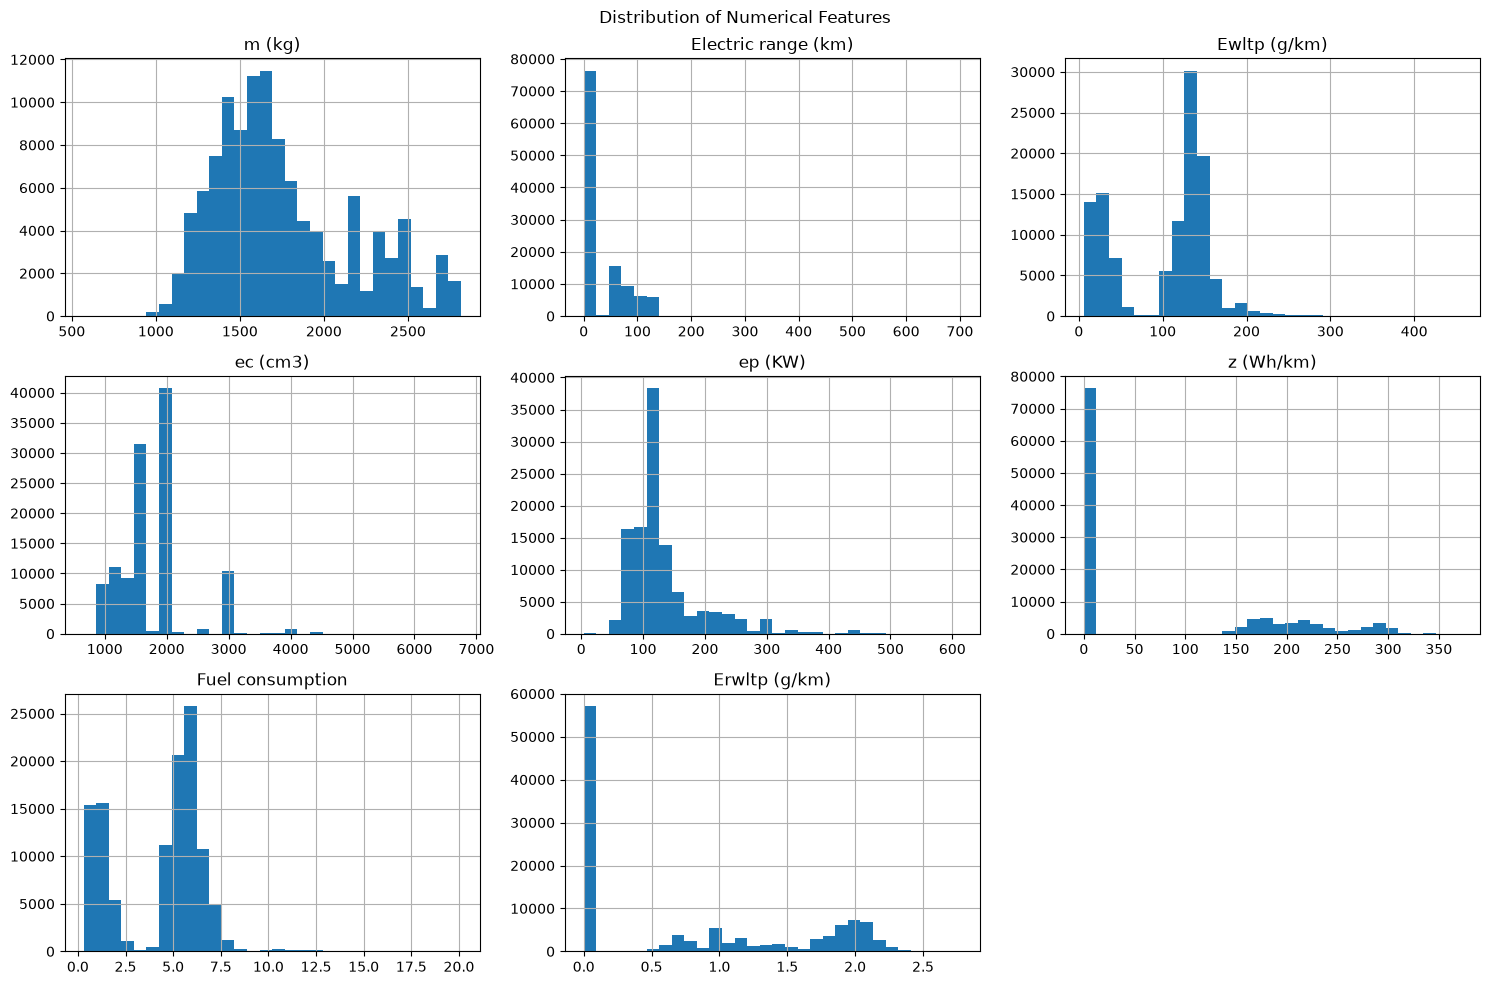

--- Feature Skewness ---
m (kg)                 0.754098
Electric range (km)    1.250937
Ewltp (g/km)          -0.265411
ec (cm3)               1.426986
ep (KW)                2.217008
z (Wh/km)              0.934456
Fuel consumption      -0.237591
Erwltp (g/km)          0.469877
dtype: float64


In [8]:
def dist_graphs():
    num_cols = [
        "m (kg)", "Electric range (km)", "Ewltp (g/km)", "ec (cm3)", "ep (KW)", "z (Wh/km)", "Fuel consumption", "Erwltp (g/km)"]
    
    # Keep only columns that actually exist in your dataset to avoid errors
    existing_num_cols = [col for col in num_cols if col in df_2024.columns]

    # Visual inspection of distributions
    df_2024[existing_num_cols].hist(bins=30, figsize=(15, 10))
    plt.suptitle("Distribution of Numerical Features")
    plt.tight_layout()
    plt.show()

    # Print Skewness to verify outlier presence
    print("--- Feature Skewness ---")
    print(df_2024[existing_num_cols].skew())
    
dist_graphs()


## Skewness measures the symmetry of a column's data distribution.

## Highly Right-Skewed (Skewness > 1.0):

* **ep (KW) (2.21)**: Strongly right-skewed with long tails to the right. Most vehicles have low-to-moderate engine power and equipment mass, with a few extreme high-performance or heavy outliers.

* **ec (cm3) (1.45)**, **Electric range (km) (1.37)**, and **z (Wh/km) (1.04)**: Moderately high right-skewness.

## Moderately Right-Skewed (0.5 to 1.0):

* **m (kg) (0.82)**: Fairly right-skewed mass data.

## Symmetric / Approximately Normal (-0.5 to 0.5):

* **Ewltp (g/km) (-0.31), Erwltp (g/km) (0.43), Fuel consumption (-0.27)**: Slightly negative or positive, but generally well-behaved and close to symmetric.


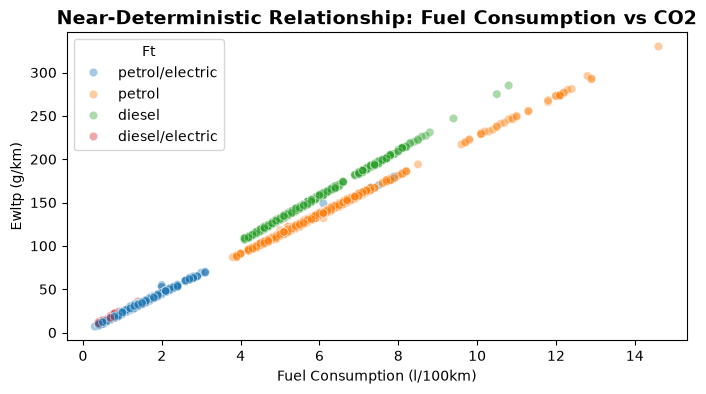

In [9]:
plt.figure(figsize=(8, 4))

combustion_df = df_2024[df_2024['Fuel consumption'] > 0]

sns.scatterplot(
    data=combustion_df.sample(5000, random_state=42), 
    x='Fuel consumption', 
    y='Ewltp (g/km)', 
    hue='Ft',
    alpha=0.4
)
plt.title('Near-Deterministic Relationship: Fuel Consumption vs CO2', fontsize=14, fontweight='bold')
plt.xlabel('Fuel Consumption (l/100km)')
plt.ylabel('Ewltp (g/km)')
plt.show()

## The scatter plot demonstrates a near-perfect deterministic relationship between Fuel Consumption and Ewltp (g/km), separated neatly by fuel-type constants. Including Fuel Consumption introduces catastrophic target leakage, trivialising model training ($R^2 \approx 1.0$) and blinding the algorithm to physical vehicle engineering parameters like mass and power.

## The goal is to build a predictive machine learning model that estimates emissions based on physical vehicle design specs (like weight, engine displacement, and power output)
## The decision to drop:
* Prevents Target Leakage: As the scatter plot clearly demonstrated, Fuel consumption determines $\text{CO}_2$ mathematically. Keeping it means the model isn't predicting emissions—it's just solving a basic stoichiometry formula.
* It Keeps the Model Useful for Real-World Inference: Engineers and planners use ML models to answer questions like "If we build a car with 150 kW power weighing 1,800 kg, what will its $\text{CO}_2$ emissions be?" At the design stage, official laboratory fuel consumption numbers don't exist yet.
* It Forces Learning from Physical Attributes: Once dropped, the model will be forced to learn the actual physical relationships between Equipment_Mass, ec (cm3), ep (KW), and Make_Encoded to predict Ewltp (g/km).

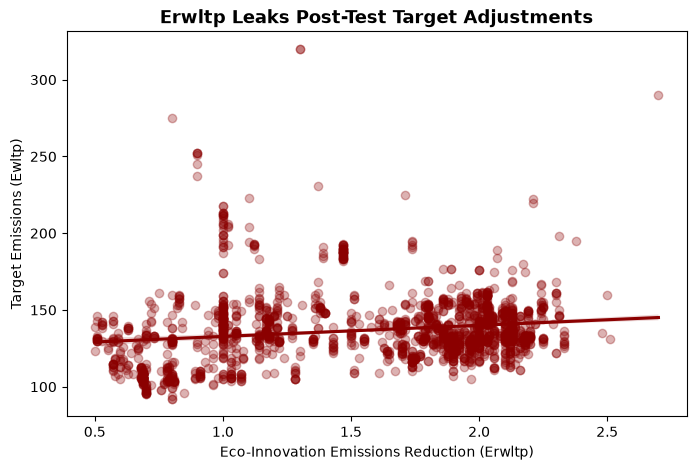

In [10]:
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df_2024[df_2024['Erwltp (g/km)'] > 0].sample(2000, random_state=42),
    x='Erwltp (g/km)', 
    y='Ewltp (g/km)',
    color='darkred',
    scatter_kws={'alpha': 0.3}
)
plt.title('Erwltp Leaks Post-Test Target Adjustments', fontsize=13, fontweight='bold')
plt.xlabel('Eco-Innovation Emissions Reduction (Erwltp)')
plt.ylabel('Target Emissions (Ewltp)')
plt.show()

## Disconnect From Raw Physics
* Cluster Stacking: The plot shows clear vertical stacks at discrete x-axis values like $1.0$, $1.5$, and $2.0\text{ g/km}$, which fits the explanation of official regulatory tiers.
* Target Emissions Range: The explanation states that target emissions span from $110$ to $190+\text{ g/km}$, but the y-axis (Target Emissions Ewltp) clearly ranges from below $100\text{ g/km}$ up to $330+\text{ g/km}$. For instance, at the $1.0\text{ g/km}$ mark on the x-axis, the points span from around $105\text{ g/km}$ up to over $220\text{ g/km}$, and there are outliers reaching $330\text{ g/km}$.
* No Direct Correlation: Across any fixed reduction value (for example, at $1.50\text{ g/km}$), target emissions span from $110\text{ g/km}$ to $190+\text{ g/km}$. The flat, weak trend line shows that Erwltp provides almost no signal regarding baseline physical vehicle attributes (like weight, displacement, or engine power).

## Target Contamination & Regulatory Leakage
* Post-Test Offsets: Under EU regulatory frameworks, Erwltp represents an administrative credit subtracted from a vehicle's certified type-approval baseline.
* Model Corruption: Because Erwltp is calculated after standardised WLTP laboratory testing, including it allows the model to access regulatory adjustment credits rather than learning physical emissions dynamics from physical parameters (Equipment_Mass, ec, ep).

# We must exclude **Fuel consumption** & **Erwltp (g/km)** columns from final feature set since they force the model to rely purely on fundamental design and engineering specifications

## Let's analyse the outliers for our numerical columns:

In [11]:
def outlier_summary():
    num_cols = [
        "m (kg)", 
        "Electric range (km)", 
        "z (Wh/km)", 
        "Ewltp (g/km)", 
        "ec (cm3)", 
        "ep (KW)",
    ]
    
    outlier_rows = []
    
    for col in num_cols:
        series = df_2024[col]
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
    
        outlier_mask = (series < lower_bound) | (series > upper_bound)
    
        outlier_rows.append({
            "column": col,
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": outlier_mask.sum(),
            "outlier_pct": round(outlier_mask.mean() * 100, 2),
            "min_outlier": series[outlier_mask].min(),
            "max_outlier": series[outlier_mask].max()
        })
     
    outlier_summary = (
        pd.DataFrame(outlier_rows)
        .set_index("column")
        .round(2)
    )
    
    display(outlier_summary)

outlier_summary()


,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_pct,min_outlier,max_outlier
column,,,,,,,,,
m (kg),1450.0,1985.0,535.0,647.5,2787.5,1194,1.05,570.0,2815.0
Electric range (km),0.0,59.0,59.0,-88.5,147.5,17,0.01,301.0,702.0
z (Wh/km),0.0,176.0,176.0,-264.0,440.0,0,0.00,NaN,NaN
Ewltp (g/km),35.0,141.0,106.0,-124.0,300.0,124,0.11,304.0,456.0
ec (cm3),1469.0,1993.0,524.0,683.0,2779.0,11671,10.25,658.0,6749.0
ep (KW),100.0,145.0,45.0,32.5,212.5,13378,11.75,4.0,614.0


#### Starting with **m (kg)** column:

**Interpretation**

The lower outliers may correspond to:

    Small city cars.

    Lightweight two-seater vehicles.

    Vehicles with small engines.

    Some electric vehicles, depending on how the dataset defines mass.

The upper outliers may correspond to:

    Large SUVs.

    Luxury vehicles.

    Vans or larger passenger vehicles.

    Plug-in hybrids with heavy battery systems.

    High-performance or large-engine vehicles.

The maximum value of 2815 kg is high, but not automatically impossible for a road vehicle. Similarly, 570 kg could represent a very small vehicle rather than a data error. 


Let's see if that's the case:

In [12]:
mkg_outliers = df_2024[
    (df_2024["m (kg)"] < 710) |
    (df_2024["m (kg)"] > 2670)
].copy()

display(mkg_outliers[[
    "Mk",
    "Cn",
    "m (kg)",
    "Ft",
    "Ewltp (g/km)",
    "ec (cm3)",
    "ep (KW)"
]].sort_values("m (kg)").head(20))

display(mkg_outliers[[
    "Mk",
    "Cn",
    "m (kg)",
    "Ft",
    "Ewltp (g/km)",
    "ec (cm3)",
    "ep (KW)"
]].sort_values("m (kg)", ascending=False).head(20))



,Mk,Cn,m (kg),Ft,Ewltp (g/km),ec (cm3),ep (KW)
115260,CATERHAM,SEVEN S3,570.0,petrol,109.0,658.0,62.0
115258,CATERHAM,SEVEN S3,570.0,petrol,109.0,658.0,62.0
115259,CATERHAM,SEVEN S3,570.0,petrol,109.0,658.0,62.0
57147,SECMA,FUN 1600,658.0,petrol,135.0,1598.0,84.0
4,SECMA,FUN 1600,658.0,petrol,142.0,1598.0,77.0
5,SECMA,FUN 1600 BUGGY,668.0,petrol,142.0,1598.0,77.0
57148,SECMA,FUN 1600 BUGGY,668.0,petrol,135.0,1598.0,84.0
49614,CATERHAM,SEVEN S3,700.0,petrol,148.0,1999.0,127.0
49613,CATERHAM,SEVEN S3,700.0,petrol,148.0,1999.0,127.0
49611,CATERHAM,SEVEN S3,700.0,petrol,148.0,1999.0,127.0


,Mk,Cn,m (kg),Ft,Ewltp (g/km),ec (cm3),ep (KW)
38937,MERCEDES-BENZ,MAYBACH GLS 600,2815.0,petrol,319.0,3982.0,410.0
38938,MERCEDES-BENZ,MAYBACH GLS 600,2815.0,petrol,316.0,3982.0,410.0
44030,LAND ROVER,RANGE ROVER,2810.0,petrol/electric,19.0,2996.0,294.0
44372,LAND ROVER,RANGE ROVER SPORT,2810.0,petrol/electric,19.0,2996.0,294.0
44383,LAND ROVER,RANGE ROVER SPORT,2810.0,petrol/electric,19.0,2996.0,294.0
44382,LAND ROVER,RANGE ROVER SPORT,2810.0,petrol/electric,19.0,2996.0,294.0
44381,LAND ROVER,RANGE ROVER SPORT,2810.0,petrol/electric,19.0,2996.0,294.0
44380,LAND ROVER,RANGE ROVER SPORT,2810.0,petrol/electric,19.0,2996.0,294.0
44379,LAND ROVER,RANGE ROVER SPORT,2810.0,petrol/electric,19.0,2996.0,294.0
44378,LAND ROVER,RANGE ROVER SPORT,2810.0,petrol/electric,19.0,2996.0,294.0


#### So we don't remove **m (kg)** outliers solely because they fall outside the IQR bounds. Vehicle mass is a meaningful predictor of **Ewltp (g/km)**, and removing heavy or lightweight vehicles could make the model less representative.

#### Let's continue with **Electric range (km)** column:

In [13]:
electric_range_outliers = df_2024[
    df_2024["Electric range (km)"] > 145
].copy()

electric_range_outliers[
    [
        "Mk",
        "Cn",
        "Ft",
        "Fm",
        "Electric range (km)",
        "z (Wh/km)",
        "Ewltp (g/km)",
        "ep (KW)",
        "m (kg)",
    ]
].sort_values("Electric range (km)", ascending=False).head(10)



,Mk,Cn,Ft,Fm,Electric range (km),z (Wh/km),Ewltp (g/km),ep (KW),m (kg)
7904,MINI,COUNTRYMAN COOPER SE ALL4,petrol/electric,P,702.0,125.0,41.0,92.0,1790.0
95570,VOLKSWAGEN,TIGUAN,petrol/electric,P,530.0,222.0,33.0,110.0,1816.0
7896,MINI,COUNTRYMAN COOPER SE ALL4,petrol/electric,P,522.0,173.0,41.0,92.0,1790.0
7913,MINI,COUNTRYMAN COOPER SE ALL4,petrol/electric,P,522.0,173.0,41.0,92.0,1790.0
7933,MINI,COUNTRYMAN COOPER SE ALL4,petrol/electric,P,522.0,173.0,42.0,92.0,1790.0
95614,VOLKSWAGEN,TIGUAN,petrol/electric,P,503.0,150.0,32.0,110.0,1801.0
95610,VOLKSWAGEN,TIGUAN,petrol/electric,P,310.0,191.0,32.0,110.0,1801.0
96411,VOLKSWAGEN,TIGUAN,petrol/electric,P,310.0,191.0,35.0,110.0,1801.0
95647,VOLKSWAGEN,TIGUAN,petrol/electric,P,310.0,191.0,34.0,110.0,1801.0
95611,VOLKSWAGEN,TIGUAN,petrol/electric,P,310.0,191.0,33.0,110.0,1801.0


The official WLTP electric range for the **MINI Countryman SE ALL4** is **up to 424 to 467 km** (depending on the model year and updates, with newer 2026 technical revisions reaching up to 467 km WLTP)

So we clearly have a corrupt data here.
702 may be:

    A data-entry / unit / field-mapping error.

    A value intended for another metric, such as total driving range rather than electric-only range.

    A value shifted from another column during extraction or transformation.

    A duplicated or incorrect source entry.

It should not be treated as a normal, high electric-range EV value for this particular record.

In [14]:
# 1. Create a Boolean mask: True = row should be investigated / removed
mask_suspicious_phev = (
    (df_2024["Ft"] == "petrol/electric")
    & (df_2024["Electric range (km)"] > 200)
)

# 2. Create a DataFrame containing only those rows
suspicious_phev_range = df_2024.loc[mask_suspicious_phev].copy()

# 3. Display the suspicious records
display(
    suspicious_phev_range[
        [
            "Mk",
            "Cn",
            "Ft",
            "Fm",
            "Electric range (km)",
            "z (Wh/km)",
            "Ewltp (g/km)",
            "ep (KW)",
            "m (kg)",
        ]
    ].sort_values("Electric range (km)", ascending=False)
)

# 4. Count rows and calculate percentage
print("Rows to remove:", mask_suspicious_phev.sum())
print(f"Percentage of all rows: {mask_suspicious_phev.mean() * 100:.4f}%")

# 5. Describe the suspicious electric-range values
print(
    suspicious_phev_range["Electric range (km)"].describe()
)

,Mk,Cn,Ft,Fm,Electric range (km),z (Wh/km),Ewltp (g/km),ep (KW),m (kg)
7904,MINI,COUNTRYMAN COOPER SE ALL4,petrol/electric,P,702.0,125.0,41.0,92.0,1790.0
95570,VOLKSWAGEN,TIGUAN,petrol/electric,P,530.0,222.0,33.0,110.0,1816.0
7896,MINI,COUNTRYMAN COOPER SE ALL4,petrol/electric,P,522.0,173.0,41.0,92.0,1790.0
7913,MINI,COUNTRYMAN COOPER SE ALL4,petrol/electric,P,522.0,173.0,41.0,92.0,1790.0
7933,MINI,COUNTRYMAN COOPER SE ALL4,petrol/electric,P,522.0,173.0,42.0,92.0,1790.0
95614,VOLKSWAGEN,TIGUAN,petrol/electric,P,503.0,150.0,32.0,110.0,1801.0
95610,VOLKSWAGEN,TIGUAN,petrol/electric,P,310.0,191.0,32.0,110.0,1801.0
96411,VOLKSWAGEN,TIGUAN,petrol/electric,P,310.0,191.0,35.0,110.0,1801.0
95647,VOLKSWAGEN,TIGUAN,petrol/electric,P,310.0,191.0,34.0,110.0,1801.0
95611,VOLKSWAGEN,TIGUAN,petrol/electric,P,310.0,191.0,33.0,110.0,1801.0


Rows to remove: 17
Percentage of all rows: 0.0149%
count     17.000000
mean     393.176471
std      126.682791
min      301.000000
25%      310.000000
50%      310.000000
75%      522.000000
max      702.000000
Name: Electric range (km), dtype: float64


#### Let's remove them:

In [15]:
df_2024 = df_2024.loc[~mask_suspicious_phev]

#### Next we continue with **z (Wh/km):**

There are no IQR outliers.

Zeros here are structural: 0 Wh/km for petrol or diesel cars generally means they do not consume grid electricity.

A high Wh/km figure can be physically plausible for a large, heavy SUV or performance EV; it is not automatically bad data.



In [16]:
high_z = df_2024.loc[
    df_2024["z (Wh/km)"] >= 430,
    [
        "Mk",
        "Cn",
        "Ft",
        "Fm",
        "z (Wh/km)",
        "Electric range (km)",
        "Ewltp (g/km)",
        "ep (KW)",
        "m (kg)",
    ],
].sort_values("z (Wh/km)", ascending=False)

display(high_z.head(30))

,Mk,Cn,Ft,Fm,z (Wh/km),Electric range (km),Ewltp (g/km),ep (KW),m (kg)


#### Next, we continue with **Ewltp (g/km)**

In [17]:
# Let's inspect the upper tail:

high_co2 = df_2024.loc[
    df_2024["Ewltp (g/km)"] > 297,
    [
        "Mk",
        "Cn",
        "Ft",
        "Fm",
        "Ewltp (g/km)",
        "Fuel consumption",
        "ec (cm3)",
        "ep (KW)",
        "m (kg)",
    ],
].sort_values("Ewltp (g/km)", ascending=False)

display(high_co2.head(30))

# compare CO2 with Fuel consumptions:
df_2024.groupby("Ft").agg(
    n=("Ewltp (g/km)", "size"),
    median_co2=("Ewltp (g/km)", "median"),
    mean_co2=("Ewltp (g/km)", "mean"),
    max_co2=("Ewltp (g/km)", "max"),
    median_fuel=("Fuel consumption", "median"),
    max_fuel=("Fuel consumption", "max"),
).round(2)

# Examine CO2 by fuel type:
df_2024.groupby("Ft")["Ewltp (g/km)"].describe().round(2)

,Mk,Cn,Ft,Fm,Ewltp (g/km),Fuel consumption,ec (cm3),ep (KW),m (kg)
25995,MERCEDES-BENZ,AMG G 63,petrol,M,456.0,20.1,3982.0,430.0,2595.0
30743,MERCEDES-BENZ,AMG G 63,petrol,M,456.0,16.2,3982.0,430.0,2595.0
19335,AUTOMOBILI LAMBORGHINI S.P.A.,AVENTADOR,petrol,M,448.0,18.0,6498.0,566.0,1765.0
57167,FERRARI,FERRARI PUROSANGUE,petrol,M,393.0,17.3,6496.0,529.0,2245.0
57168,FERRARI,FERRARI PUROSANGUE,petrol,M,393.0,17.3,6496.0,529.0,2245.0
56951,FERRARI,812 COMPETIZIONE,petrol,M,385.0,16.9,6496.0,607.0,1740.0
56950,FERRARI,812 COMPETIZIONE,petrol,M,385.0,16.9,6496.0,607.0,1740.0
13,ROLLS ROYCE,CULLINAN,petrol,M,375.0,16.4,6749.0,420.0,2765.0
56952,FERRARI,812 GTS,petrol,M,373.0,16.4,6496.0,585.0,1865.0
56954,FERRARI,812 COMPETIZIONE A,petrol,M,370.0,16.3,6496.0,607.0,1810.0


,count,mean,std,min,25%,50%,75%,max
Ft,,,,,,,,
diesel,26722.0,144.72,22.13,106.0,131.0,140.0,150.00,322.0
diesel/electric,2979.0,13.37,4.01,10.0,11.0,11.0,14.00,52.0
petrol,49576.0,135.30,24.28,87.0,124.0,133.0,144.91,456.0
petrol/electric,34591.0,28.28,13.30,6.0,19.0,28.0,35.00,276.0


Although 135 values exceeded the IQR upper fence of 297 g/km, manual inspection showed that they represent high-performance and heavy petrol vehicles, including Mercedes-AMG, Ferrari, Lamborghini, Rolls-Royce, Bentley, Aston Martin, and large SUVs. Their CO2 values were consistent with high engine displacement, engine power, vehicle mass, and fuel consumption. Therefore, they were retained as valid observations.

#### Next, **ec (cm3)**

In [18]:
# small lower tail

small_engine = df_2024.loc[
    df_2024["ec (cm3)"] < 660,
    [
        "Mk",
        "Cn",
        "Ft",
        "Fm",
        "ec (cm3)",
        "ep (KW)",
        "m (kg)",
        "Fuel consumption",
        "Ewltp (g/km)",
    ],
].sort_values("ec (cm3)")

display(small_engine.head(30))

# high end
large_engine = df_2024.loc[
    df_2024["ec (cm3)"] > 2796,
    [
        "Mk",
        "Cn",
        "Ft",
        "Fm",
        "ec (cm3)",
        "ep (KW)",
        "m (kg)",
        "Fuel consumption",
        "Ewltp (g/km)",
    ],
].sort_values("ec (cm3)", ascending=False)

display(large_engine.head(30))

,Mk,Cn,Ft,Fm,ec (cm3),ep (KW),m (kg),Fuel consumption,Ewltp (g/km)
115258,CATERHAM,SEVEN S3,petrol,M,658.0,62.0,570.0,4.8,109.0
115259,CATERHAM,SEVEN S3,petrol,M,658.0,62.0,570.0,4.8,109.0
115260,CATERHAM,SEVEN S3,petrol,M,658.0,62.0,570.0,4.8,109.0


,Mk,Cn,Ft,Fm,ec (cm3),ep (KW),m (kg),Fuel consumption,Ewltp (g/km)
9,ROLLS ROYCE,GHOST,petrol,M,6749.0,420.0,2565.0,15.5,353.0
13,ROLLS ROYCE,CULLINAN,petrol,M,6749.0,420.0,2765.0,16.4,375.0
14,ROLLS ROYCE,CULLINAN,petrol,M,6749.0,420.0,2765.0,16.2,370.0
15,ROLLS ROYCE,PHANTOM EWB,petrol,M,6749.0,420.0,2795.0,16.0,362.0
16,ROLLS ROYCE,CULLINAN,petrol,M,6749.0,420.0,2800.0,16.2,366.0
19335,AUTOMOBILI LAMBORGHINI S.P.A.,AVENTADOR,petrol,M,6498.0,566.0,1765.0,18.0,448.0
47206,AUTOMOBILI LAMBORGHINI S.P.A.,REVUELTO,petrol/electric,P,6498.0,607.0,1967.0,11.9,276.0
47205,AUTOMOBILI LAMBORGHINI S.P.A.,REVUELTO,petrol/electric,P,6498.0,607.0,1967.0,11.9,276.0
56953,FERRARI,812 COMPETIZIONE A,petrol,M,6496.0,607.0,1810.0,16.3,370.0
57168,FERRARI,FERRARI PUROSANGUE,petrol,M,6496.0,529.0,2245.0,17.3,393.0


Although a number of ec (cm3) values lie outside the IQR interval of 660 - 2796 cm3, inspection showed that lower-tail observations represent lightweight small-engine vehicles, while upper-tail observations are large-displacement luxury and performance vehicles. The associated power, mass, fuel consumption, and WLTP CO2 values are internally consistent. 
Therefore, no engine-capacity observations will be removed or capped.

#### Next, **ep (KW)**

Although a number of ep (KW) values lie outside the IQR interval of 22.5 - 218.5 kW, inspection showed that low-power outliers represent small or low-output vehicles, while high-power outliers are performance and luxury vehicles. Power values are consistent with engine capacity, mass, fuel consumption, and WLTP CO2. Therefore, no engine-power observations were removed or capped.

# Now, let's see the summary and the distribution graphs again:

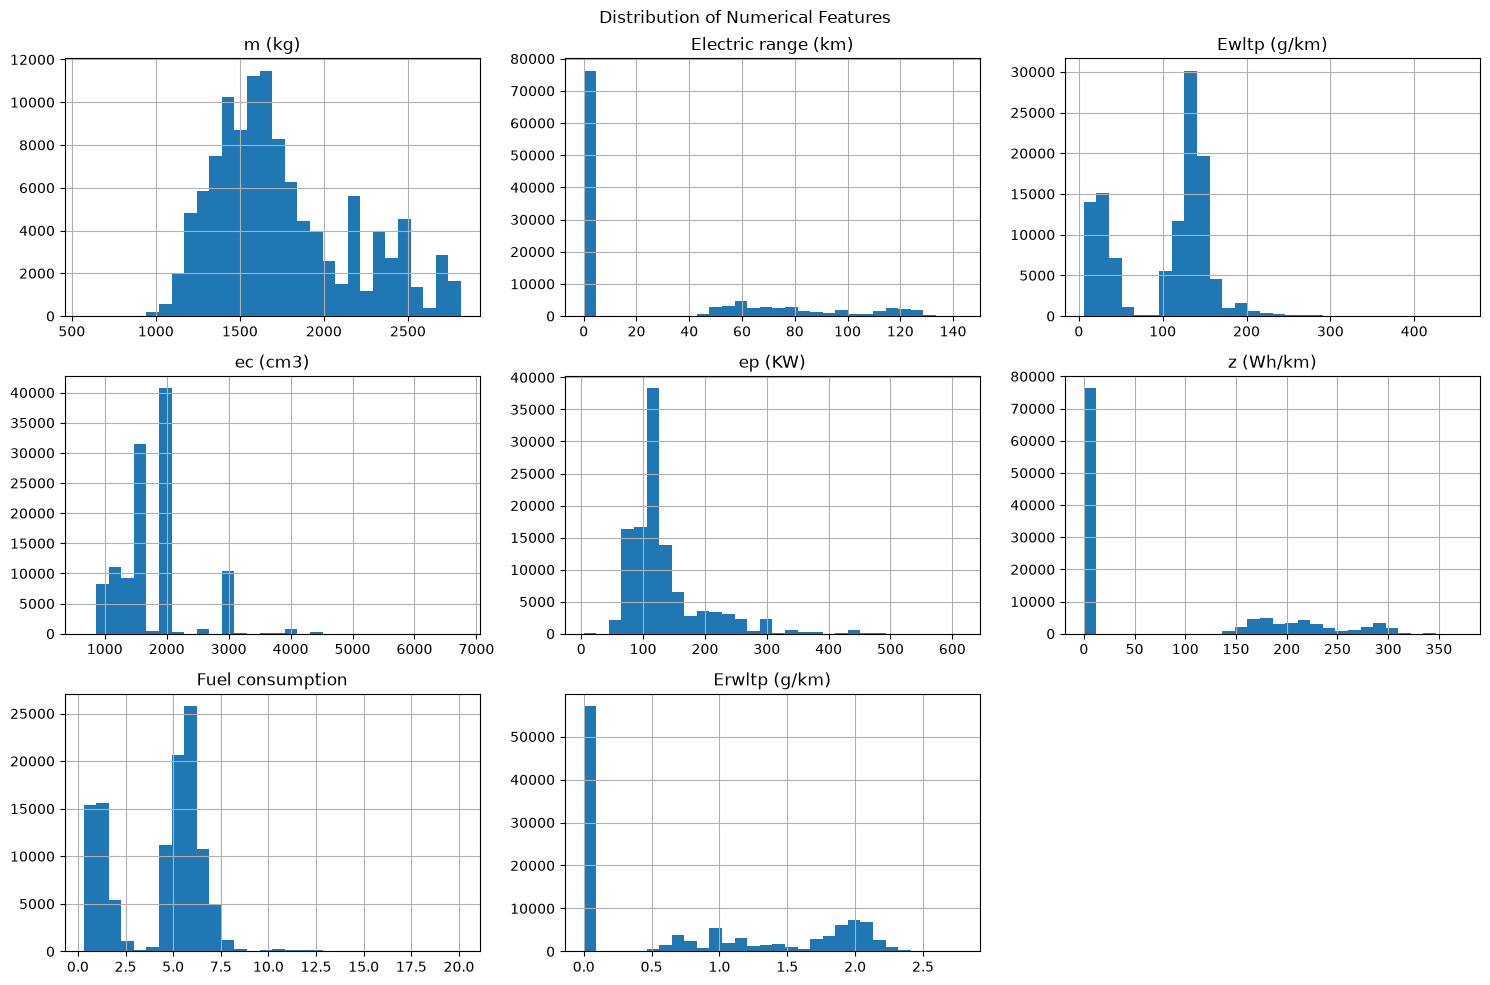

--- Feature Skewness ---
m (kg)                 0.754096
Electric range (km)    1.134213
Ewltp (g/km)          -0.265756
ec (cm3)               1.426764
ep (KW)                2.216764
z (Wh/km)              0.934902
Fuel consumption      -0.237929
Erwltp (g/km)          0.469633
dtype: float64


,dtype,missing_count,missing_pct,zero_count,zero_pct,unique_values,min,q1,median,q3,max
m (kg),float64,0,0.0,0,0.00,1077,570.0,1450.0,1655.0,1985.00,2815.00
Electric range (km),float64,0,0.0,76298,67.01,117,0.0,0.0,0.0,59.00,143.00
z (Wh/km),float64,0,0.0,76298,67.01,207,0.0,0.0,0.0,176.00,372.00
Ewltp (g/km),float64,0,0.0,0,0.00,2246,6.0,35.0,127.0,141.00,456.00
ec (cm3),float64,0,0.0,0,0.00,90,658.0,1469.0,1598.0,1993.00,6749.00
ep (KW),float64,0,0.0,0,0.00,195,4.0,100.0,110.0,145.00,614.00
Erwltp (g/km),float64,0,0.0,57141,50.18,184,0.0,0.0,0.0,1.75,2.78
Fuel consumption,float64,0,0.0,0,0.00,154,0.3,1.5,5.2,5.90,20.10


Shape: (113868, 22)

Dtypes:
 VFN                        str
Tan                        str
T                          str
Va                         str
Ve                         str
Mk                         str
Cn                         str
Ct                         str
m (kg)                 float64
Mt                     float64
Ft                         str
Fm                         str
ec (cm3)               float64
ep (KW)                float64
z (Wh/km)              float64
IT                         str
Erwltp (g/km)          float64
Fuel consumption       float64
RLFI                       str
Electric range (km)    float64
r                        int64
Ewltp (g/km)           float64
dtype: object

NaN counts:
 VFN                     0
Tan                     0
T                       0
Va                      0
Ve                      1
Mk                      0
Cn                      0
Ct                      0
m (kg)                  0
Mt                      0


In [19]:
dist_graphs()

def summary():
    
    num_cols = [
        "m (kg)", 
        "Electric range (km)", 
        "z (Wh/km)", 
        "Ewltp (g/km)", 
        "ec (cm3)", 
        "ep (KW)", 
        "Erwltp (g/km)",
        "Fuel consumption",
    ]
    
    preprocessing_summary = pd.DataFrame({
        "dtype": df_2024[num_cols].dtypes.astype(str),
        "missing_count": df_2024[num_cols].isna().sum(),
        "missing_pct": (df_2024[num_cols].isna().mean() * 100).round(2),
        "zero_count": (df_2024[num_cols] == 0).sum(),
        "zero_pct": ((df_2024[num_cols] == 0).mean() * 100).round(2),
        "unique_values": df_2024[num_cols].nunique(),
        "min": df_2024[num_cols].min(),
        "q1": df_2024[num_cols].quantile(0.25),
        "median": df_2024[num_cols].median(),
        "q3": df_2024[num_cols].quantile(0.75),
        "max": df_2024[num_cols].max()
    }).round(2)
    
    display(preprocessing_summary)

summary()

print("Shape:", df_2024.shape)
print("\nDtypes:\n", df_2024.dtypes)
print("\nNaN counts:\n", df_2024.isna().sum())
print("\nTarget stats:\n", df_2024["Ewltp (g/km)"].describe())

## Now we need to split train and test so that we encode the categorical columns amd implement standardization/normalization on the numerical ones.

### Let's export our dataframe:

In [20]:
df_2024.to_csv("../data/processed/EU/2024_FR_cleaned_final.csv", index = False)


In [21]:
df_2024.describe(include='all')

,VFN,Tan,T,Va,Ve,Mk,Cn,Ct,m (kg),Mt,...,ec (cm3),ep (KW),z (Wh/km),IT,Erwltp (g/km),Fuel consumption,RLFI,Electric range (km),r,Ewltp (g/km)
count,113868,113868,113868,113868,113867,113868,113868,113868,113868.000000,113868.000000,...,113868.000000,113868.000000,113868.000000,113868,113868.000000,113868.000000,113839,113868.000000,113868.000000,113868.000000
unique,2288,1482,320,1539,5915,54,737,2,NaN,NaN,...,NaN,NaN,NaN,80,NaN,NaN,1110,NaN,NaN,NaN
top,IP-HNA1M2PDB1A_000-VF1,E1*2018/858*00153*06,F,R,EAW50000,BMW,TIGUAN,M1,NaN,NaN,...,NaN,NaN,NaN,none,NaN,NaN,RL-2021_0145-W1K-1,NaN,NaN,NaN
freq,1464,1768,5977,2914,2477,18268,3105,112272,NaN,NaN,...,NaN,NaN,NaN,57141,NaN,NaN,2866,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1754.086574,1894.146591,...,1775.819150,132.099826,71.574095,NaN,0.769902,4.287752,NaN,26.926424,12.589586,101.807336
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,413.751861,433.408186,...,569.848465,62.088577,105.464110,NaN,0.857112,2.354162,NaN,41.098617,88.954270,56.507098
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,570.000000,616.000000,...,658.000000,4.000000,0.000000,NaN,0.000000,0.300000,NaN,0.000000,1.000000,6.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1450.000000,1576.000000,...,1469.000000,100.000000,0.000000,NaN,0.000000,1.500000,NaN,0.000000,1.000000,35.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1655.000000,1793.000000,...,1598.000000,110.000000,0.000000,NaN,0.000000,5.200000,NaN,0.000000,1.000000,127.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1985.000000,2136.000000,...,1993.000000,145.000000,176.000000,NaN,1.750000,5.900000,NaN,59.000000,3.000000,141.000000


In [22]:
# ======================================================
# 0) Metadata routing
# ======================================================

set_config(enable_metadata_routing=True)

# ======================================================
# 1) Copy data and create groups
# ======================================================

df_clean = df_2024.copy()

raw_group_features = [
    # "Make_Grouped" does not exist yet; it will be added below
    "Cn",
    "VFN",
    "Tan",
    "T",
    "Va",
    "Ve",
    "Ct",
    "RLFI",
    "m (kg)",
    "Mt",
    "Ft",
    "Fm",
    "ec (cm3)",
    "ep (KW)",
    "z (Wh/km)",
    "Electric range (km)",
    "IT",
]

group_id = (
    df_clean
    .groupby(
        raw_group_features,
        dropna=False,
    )
    .ngroup()
)

target_column = "Ewltp (g/km)"

# ======================================================
# 2) Group-based train/test split
# ======================================================

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx, test_idx = next(
    gss.split(
        df_clean,
        y=df_clean[target_column],
        groups=group_id,
    )
)

X_train_group_raw = df_clean.iloc[train_idx].copy()
X_test_group_raw = df_clean.iloc[test_idx].copy()

train_group_ids = group_id.iloc[train_idx].to_numpy()
test_group_ids = group_id.iloc[test_idx].to_numpy()

train_groups = set(train_group_ids)
test_groups = set(test_group_ids)

print("Number of train lines:", len(X_train_group_raw))
print("Number of test lines:", len(X_test_group_raw))
print("Number of train groups:", len(train_groups))
print("Number of test groups:", len(test_groups))
print(
    "Number of common train-test groups:",
    len(train_groups.intersection(test_groups)),
)

assert len(train_groups.intersection(test_groups)) == 0

# ======================================================
# 2.5) Make_Grouped: top 30 based only on X_train
# ======================================================

# Let's not remove the target column just yet; Mk is still there.
# We will work on X_train_group_raw and X_test_group_raw.

top_makes = (
    X_train_group_raw["Mk"]
    .value_counts()
    .nlargest(30)
    .index
)

for frame in [X_train_group_raw, X_test_group_raw]:
    frame["Make_Grouped"] = frame["Mk"].where(
        frame["Mk"].isin(top_makes),
        "OTHER"
    )

# Now we have Make_Grouped; we will use it in the subsequent steps.

# ======================================================
# 3) Separate target
# ======================================================

y_train = X_train_group_raw[target_column].copy()
y_test = X_test_group_raw[target_column].copy()

columns_to_drop = [
    target_column,
    "Erwltp (g/km)",
    "Fuel consumption",
    "Mt",
]

X_train = X_train_group_raw.drop(
    columns=columns_to_drop
).copy()

X_test = X_test_group_raw.drop(
    columns=columns_to_drop
).copy()

print("Train columns after initial drop:")
print(X_train.columns.tolist())

# ======================================================
# 4) Frequency encoding helper
# ======================================================

def add_frequency_feature(
    train_frame,
    test_frame,
    source_column,
    output_column,
):
    frequency_map = train_frame[source_column].value_counts(
        dropna=False
    )

    train_frame[output_column] = (
        train_frame[source_column]
        .map(frequency_map)
        .fillna(0)
        .astype("int32")
    )

    test_frame[output_column] = (
        test_frame[source_column]
        .map(frequency_map)
        .fillna(0)
        .astype("int32")
    )

    return train_frame, test_frame

# ======================================================
# 5) Frequency encoding
# ======================================================

frequency_columns = {
    "Cn": "Model_Frequency",
    "VFN": "VFN_Frequency",
    "Tan": "Tan_Frequency",
    "T": "T_Frequency",
    "Va": "Va_Frequency",
    "Ve": "Ve_Frequency",
    "Ct": "Ct_Frequency",
    "RLFI": "RLFI_Frequency",
}

for source_column, output_column in frequency_columns.items():
    X_train, X_test = add_frequency_feature(
        train_frame=X_train,
        test_frame=X_test,
        source_column=source_column,
        output_column=output_column,
    )

# ======================================================
# 6) IT encoding
# ======================================================

IT_CODES = [
    "28",
    "29",
    "32",
    "33",
    "37",
    "none",
]

def extract_it_tokens(value):
    return re.findall(
        r"\b\d+\b|\bnone\b",
        str(value).lower(),
    )

def encode_it_columns(frame, it_column="IT"):
    result = frame.copy()

    it_tokens = result[it_column].map(
        extract_it_tokens
    )

    for code in IT_CODES:
        result[f"IT_{code}"] = (
            it_tokens
            .map(lambda tokens: int(code in tokens))
            .astype("int8")
        )

    return result.drop(
        columns=[it_column]
    )

X_train = encode_it_columns(
    X_train,
    it_column="IT",
)
X_test = encode_it_columns(
    X_test,
    it_column="IT",
)

it_columns = [
    f"IT_{code}"
    for code in IT_CODES
]

# ======================================================
# 7) Group-aware target encoding for Make_Grouped
# ======================================================

target_encoder_cv = GroupKFold(
    n_splits=5,
)

make_target_encoder = TargetEncoder(
    smooth="auto",
    target_type="continuous",
    cv=target_encoder_cv,
)

X_train_make_encoded = (
    make_target_encoder.fit_transform(
        X_train[["Make_Grouped"]],
        y_train,
        groups=train_group_ids,
    )
)

X_test_make_encoded = (
    make_target_encoder.transform(
        X_test[["Make_Grouped"]]
    )
)

X_train["Make_Encoded"] = (
    X_train_make_encoded[:, 0]
)
X_test["Make_Encoded"] = (
    X_test_make_encoded[:, 0]
)

print("Make target encoder completed.")

print(
    "Train Make_Encoded missing:",
    X_train["Make_Encoded"].isna().sum(),
)

print(
    "Test Make_Encoded missing:",
    X_test["Make_Encoded"].isna().sum(),
)

# ======================================================
# 8) Drop raw categorical / ID-like columns
# ======================================================

columns_to_drop_after_encoding = [
    "Mk",
    "Cn",
    "Make_Grouped",
    "VFN",
    "Tan",
    "T",
    "Va",
    "Ve",
    "Ct",
    "RLFI",
]

X_train_model_input = X_train.drop(
    columns=columns_to_drop_after_encoding
).copy()

X_test_model_input = X_test.drop(
    columns=columns_to_drop_after_encoding
).copy()

print(
    "Model input train columns:"
)
print(
    X_train_model_input.columns.tolist()
)

print(
    "\nModel input test columns:"
)
print(
    X_test_model_input.columns.tolist()
)

assert list(
    X_train_model_input.columns
) == list(
    X_test_model_input.columns
)

# ======================================================
# 9) One-hot encode Ft and Fm
# ======================================================

onehot_columns = [
    "Ft",
    "Fm",
]

fuel_onehot_pipeline = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "fuel_onehot",
            fuel_onehot_pipeline,
            onehot_columns,
        ),
    ],
    remainder="passthrough",
    sparse_threshold=0,
)

X_train_encoded_array = (
    preprocessor.fit_transform(
        X_train_model_input
    )
)
X_test_encoded_array = (
    preprocessor.transform(
        X_test_model_input
    )
)

fuel_encoder = (
    preprocessor
    .named_transformers_["fuel_onehot"]
    .named_steps["onehot"]
)

fuel_cols = (
    fuel_encoder
    .get_feature_names_out(onehot_columns)
    .tolist()
)

remainder_cols = [
    col
    for col in X_train_model_input.columns
    if col not in onehot_columns
]

all_columns = fuel_cols + remainder_cols

X_train_encoded = pd.DataFrame(
    X_train_encoded_array,
    columns=all_columns,
    index=X_train_model_input.index,
)

X_test_encoded = pd.DataFrame(
    X_test_encoded_array,
    columns=all_columns,
    index=X_test_model_input.index,
)

# ======================================================
# 10) Validation checks
# ======================================================

print(
    "X_train_encoded shape:",
    X_train_encoded.shape,
)

print(
    "X_test_encoded shape:",
    X_test_encoded.shape,
)

print(
    "Number of output columns:",
    len(all_columns),
)

print(
    "Missing values in X_train_encoded:",
    int(
        X_train_encoded.isna().sum().sum()
    ),
)

print(
    "Missing values in X_test_encoded:",
    int(
        X_test_encoded.isna().sum().sum()
    ),
)

print(
    "Unseen Model rows in test:",
    int(
        (X_test["Model_Frequency"] == 0).sum()
    ),
)

print(
    "IT columns:",
    it_columns,
)

print(
    "Output columns:",
    X_train_encoded.columns.tolist(),
)

assert list(
    X_train_encoded.columns
) == list(
    X_test_encoded.columns
)

assert (
    X_train_encoded.isna().sum().sum()
    == 0
)

assert (
    X_test_encoded.isna().sum().sum()
    == 0
)

Number of train lines: 91122
Number of test lines: 22746
Number of train groups: 86765
Number of test groups: 21692
Number of common train-test groups: 0
Train columns after initial drop:
['VFN', 'Tan', 'T', 'Va', 'Ve', 'Mk', 'Cn', 'Ct', 'm (kg)', 'Ft', 'Fm', 'ec (cm3)', 'ep (KW)', 'z (Wh/km)', 'IT', 'RLFI', 'Electric range (km)', 'r', 'Make_Grouped']
Make target encoder completed.
Train Make_Encoded missing: 0
Test Make_Encoded missing: 0
Model input train columns:
['m (kg)', 'Ft', 'Fm', 'ec (cm3)', 'ep (KW)', 'z (Wh/km)', 'Electric range (km)', 'r', 'Model_Frequency', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'Ct_Frequency', 'RLFI_Frequency', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_none', 'Make_Encoded']

Model input test columns:
['m (kg)', 'Ft', 'Fm', 'ec (cm3)', 'ep (KW)', 'z (Wh/km)', 'Electric range (km)', 'r', 'Model_Frequency', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'Ct_Frequency', 'RLFI_

### Now let's scale our data

In [23]:
X_train_encoded.head()

,Ft_diesel,Ft_diesel/electric,Ft_petrol,Ft_petrol/electric,Fm_H,Fm_M,Fm_P,m (kg),ec (cm3),ep (KW),...,Ve_Frequency,Ct_Frequency,RLFI_Frequency,IT_28,IT_29,IT_32,IT_33,IT_37,IT_none,Make_Encoded
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2272.0,3996.0,478.0,...,1.0,1286.0,21.0,0.0,1.0,0.0,0.0,0.0,0.0,162.327528
1,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1575.0,3456.0,298.0,...,58.0,89836.0,21.0,0.0,0.0,0.0,0.0,0.0,1.0,161.372224
2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1575.0,3456.0,298.0,...,59.0,89836.0,21.0,0.0,0.0,0.0,0.0,0.0,1.0,159.059517
4,0.0,0.0,1.0,0.0,0.0,1.0,0.0,658.0,1598.0,77.0,...,58.0,89836.0,8.0,0.0,0.0,0.0,0.0,0.0,1.0,161.372224
6,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2102.0,2992.0,390.0,...,1.0,89836.0,3.0,0.0,0.0,0.0,0.0,1.0,0.0,161.372224


In [24]:
# Prepare Scaled Data (FOR LINEAR MODELS ONLY) ---
# Scale only the continuous numeric columns
numeric_cols = [
    "ec (cm3)", "ep (KW)", "m (kg)", "z (Wh/km)", 
    "Electric range (km)", "Model_Frequency", "Make_Encoded",
    "VFN_Frequency",
    "Tan_Frequency",
    "T_Frequency",
    "Va_Frequency",
    "Ve_Frequency",
    "Ct_Frequency",
    "RLFI_Frequency",
]

scaler = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), numeric_cols),
    ],
    remainder="passthrough",
)

X_train_encoded_scaled = scaler.fit_transform(X_train_encoded)
X_test_encoded_scaled = scaler.transform(X_test_encoded)


# Preserve column names (scaled columns first, remainder last)
scaled_cols = numeric_cols
remainder_cols = [col for col in X_train_encoded.columns if col not in numeric_cols]
all_columns = scaled_cols + remainder_cols

# Convert to a DataFrame
X_train_encoded_scaled = pd.DataFrame(
    X_train_encoded_scaled,
    columns=all_columns,
    index=X_train_encoded.index
)

X_test_encoded_scaled = pd.DataFrame(
    X_test_encoded_scaled,
    columns=all_columns,
    index=X_test_encoded.index
)

# Control
print("X_train_encoded_scaled shape:", X_train_encoded_scaled.shape)
print("X_train_encoded_scaled columns list:", X_train_encoded_scaled.columns.tolist())
print("X_train_encoded_scaled empty data:", X_train_encoded_scaled.isna().sum().sum())
print("X_train_encoded_scaled data types:", X_train_encoded_scaled.dtypes.value_counts())
#Print verification of scaled data (mean ≈ 0, std ≈ 1)
print("X_train_encoded_scaled scaled columns mean:\n", X_train_encoded_scaled[numeric_cols].mean().round(4))
print("\nX_train_encoded_scaled scaled columns std:\n", X_train_encoded_scaled[numeric_cols].std().round(4))
print("\n*********\n")
print("X_test_encoded_scaled shape:", X_test_encoded_scaled.shape)
print("X_test_encoded_scaled columns list:", X_test_encoded_scaled.columns.tolist())
print("X_test_encoded_scaled empty data:", X_test_encoded_scaled.isna().sum().sum())
print("X_test_encoded_scaled data types:", X_test_encoded_scaled.dtypes.value_counts())

X_train_encoded_scaled shape: (91122, 28)
X_train_encoded_scaled columns list: ['ec (cm3)', 'ep (KW)', 'm (kg)', 'z (Wh/km)', 'Electric range (km)', 'Model_Frequency', 'Make_Encoded', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'Ct_Frequency', 'RLFI_Frequency', 'Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'r', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_none']
X_train_encoded_scaled empty data: 0
X_train_encoded_scaled data types: float64    28
Name: count, dtype: int64
X_train_encoded_scaled scaled columns mean:
 ec (cm3)               0.0
ep (KW)                0.0
m (kg)                -0.0
z (Wh/km)              0.0
Electric range (km)    0.0
Model_Frequency        0.0
Make_Encoded          -0.0
VFN_Frequency         -0.0
Tan_Frequency          0.0
T_Frequency            0.0
Va_Frequency          -0.0
Ve_Frequency           0.0
Ct_Frequency          -0.0
RLFI_Frequency         0.0
dtype: floa

# Let's save our split data and artefacts:

In [25]:
artefacts_dir = Path("../artefacts")
split_dir = Path("../data/processed/eu/splits")

# If the folder doesn't exist, create it; if it does exist, don't return an error
artefacts_dir.mkdir(parents=True, exist_ok=True)
split_dir.mkdir(parents=True, exist_ok=True)

# save raw split data (not encoded, not scaled, only split)
X_train_raw = df_2024.loc[X_train.index].copy()
X_test_raw = df_2024.loc[X_test.index].copy()

X_train_raw.to_parquet(split_dir / "X_train_raw.parquet", index=True)
X_test_raw.to_parquet(split_dir / "X_test_raw.parquet", index=True)

# save encoded split data
X_train_encoded.to_parquet(split_dir / "X_train_encoded.parquet", index=True)
X_test_encoded.to_parquet(split_dir / "X_test_encoded.parquet", index=True)

# save encoded and scaled split data
X_train_encoded_scaled.to_parquet(split_dir / "X_train_encoded_scaled.parquet", index=True)
X_test_encoded_scaled.to_parquet(split_dir / "X_test_encoded_scaled.parquet", index=True)

y_train.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_train.parquet", index=True)
y_test.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_test.parquet", index=True)

# save the encoder and the scaler
joblib.dump(preprocessor, artefacts_dir / "ohe_encoder.joblib")
joblib.dump(scaler, artefacts_dir / "numeric_scaler.joblib")

# control
print("X_train_raw saved:", (split_dir / "X_train_raw.parquet").exists())
print("X_test_raw saved:", (split_dir / "X_test_raw.parquet").exists())
print("******")
print("X_train_encoded saved:", (split_dir / "X_train_encoded.parquet").exists())
print("X_test_encoded saved:", (split_dir / "X_test_encoded.parquet").exists())
print("******")
print("X_train_encoded_scaled saved:", (split_dir / "X_train_encoded_scaled.parquet").exists())
print("X_test_encoded_scaled saved:", (split_dir / "X_test_encoded_scaled.parquet").exists())
print("******")
print("y_train saved:", (split_dir / "y_train.parquet").exists())
print("y_test saved:", (split_dir / "y_test.parquet").exists())

print("******")
print("Preprocessor saved:", (artefacts_dir / "ohe_encoder.joblib").exists())
print("Scaler saved:", (artefacts_dir / "numeric_scaler.joblib").exists())

X_train_raw saved: True
X_test_raw saved: True
******
X_train_encoded saved: True
X_test_encoded saved: True
******
X_train_encoded_scaled saved: True
X_test_encoded_scaled saved: True
******
y_train saved: True
y_test saved: True
******
Preprocessor saved: True
Scaler saved: True


# Summary: Vehicle CO2 Emissions Data Preparation

## 1. Package Setup and Data Loading

The required Python data-science and machine-learning libraries were imported, including `pandas`, `numpy`, `matplotlib`, `seaborn`, scikit-learn tools, `joblib`, and `category_encoders`.

The cleaned 2024 France vehicle dataset was loaded from `2024_FR_cleaned.csv`.

The dataset initially contained **119,380 rows and 18 columns**. The non-predictive `r` column was removed because it did not provide useful information for predicting CO₂ emissions.

---

## 3. Feature Encoding

### Target Encoding — `Make_Encoded`

The grouped vehicle manufacturer feature, `Make_Grouped`, was transformed into the mean CO₂ emissions value for each manufacturer.

This preserved useful information about the relationship between vehicle manufacturer and emissions without creating a large number of one-hot-encoded columns.

### Frequency Encoding — `Model_Frequency`

Vehicle models were transformed into their occurrence frequencies in the dataset.

This represented model popularity while avoiding the very high-dimensional feature space that would result from one-hot encoding thousands of individual models.

### One-Hot Encoding — `Ft_`, `Fm_` and `IT` Features

Fuel type (`Ft`) and fuel mode (`Fm`) were converted into binary indicator columns.

One-hot encoding prevents models from incorrectly treating fuel categories as if they have an ordinal relationship.

After creating the encoded features, the original raw categorical columns were removed:

- `Mk`
- `Cn`
- `Make_Grouped`

---

## 4. Fuel Category Filtering

The distributions of fuel type (`Ft`) and fuel mode (`Fm`) were inspected before filtering.

The dataset retained the primary fuel categories:

- Petrol
- Petrol/electric
- Diesel
- Diesel/Electric

Low-frequency fuel categories were removed:

- `e85`
- `lpg`

These categories represented only a small proportion of the data and could introduce unstable or unreliable patterns during model training.

---

## 5. Target Leakage Prevention

Fuel consumption and `Erwltp` were found to be target leakage suspects.

Fuel consumption has a direct physical and stoichiometric relationship with CO₂ emissions. Including it could allow the model to predict emissions using an overly direct proxy instead of learning meaningful relationships from vehicle characteristics, such as:

- Vehicle mass
- Engine displacement
- Engine power
- Fuel type
- Vehicle manufacturer

`Erwltp` represents post-test regulatory adjustments and may contain information too closely related to the target variable.

---

## 6. Train/Test Split

The data was divided into training and test sets using an **80/20 split**:

```python
group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
) 
```

The split was performed before scaling and outlier filtering.

This helps prevent data leakage by ensuring that the test set remains a clean, unseen benchmark for final model evaluation.

---

## 7. Outlier and Data-Quality Handling

Summary statistics and numerical distributions were examined to understand feature ranges, skewness, and possible anomalies.

Histograms were used to visualize the distributions of numerical variables.

Rows where `Electric range (km)` was suspiciously high and justified to be currupt data have been removed.

---

## 8. Feature Standardization

Continuous numerical features were standardized using `StandardScaler`.

The scaler was fitted only on the training data to prevent information from the test set leaking into the training process:

```python
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
```

Standardization places numerical variables on a comparable scale, typically with:

- Mean close to `0`
- Standard deviation close to `1`

This is particularly important for models that are sensitive to feature scale, including linear models, support vector machines, k-nearest neighbors, and neural networks.